In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

long = pd.read_csv(PROC / "log_index_segments.csv")
long["ym"] = pd.PeriodIndex(long["ym"], freq="M")
COMS = sorted(long["commodity"].unique())
SEGS = ["A", "B"]

def seg_wide(seg, col):
    return long[long["segment"] == seg].pivot(index="ym", columns="commodity", values=col)

logs  = {s: seg_wide(s, "log_idx") for s in SEGS}
dlogs = {s: seg_wide(s, "dlog").dropna() for s in SEGS}

for s in SEGS:
    print(f"Segment {s}: {len(logs[s])} months, {len(dlogs[s])} monthly changes")

Segment A: 41 months, 40 monthly changes
Segment B: 74 months, 73 monthly changes


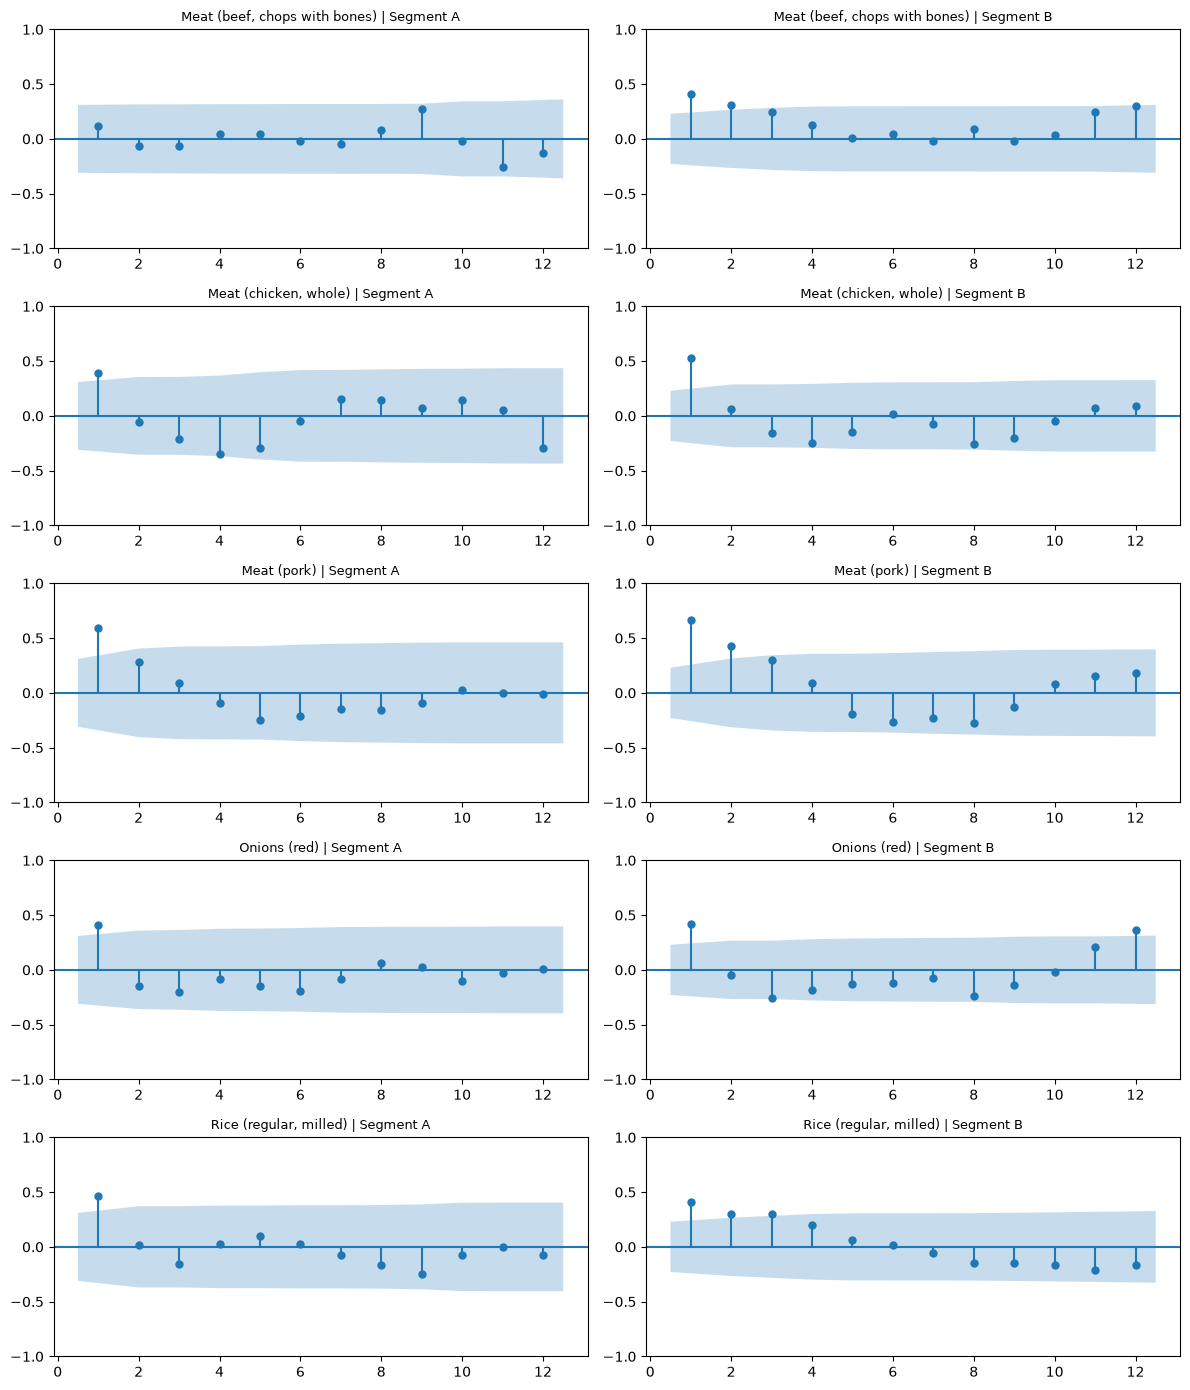

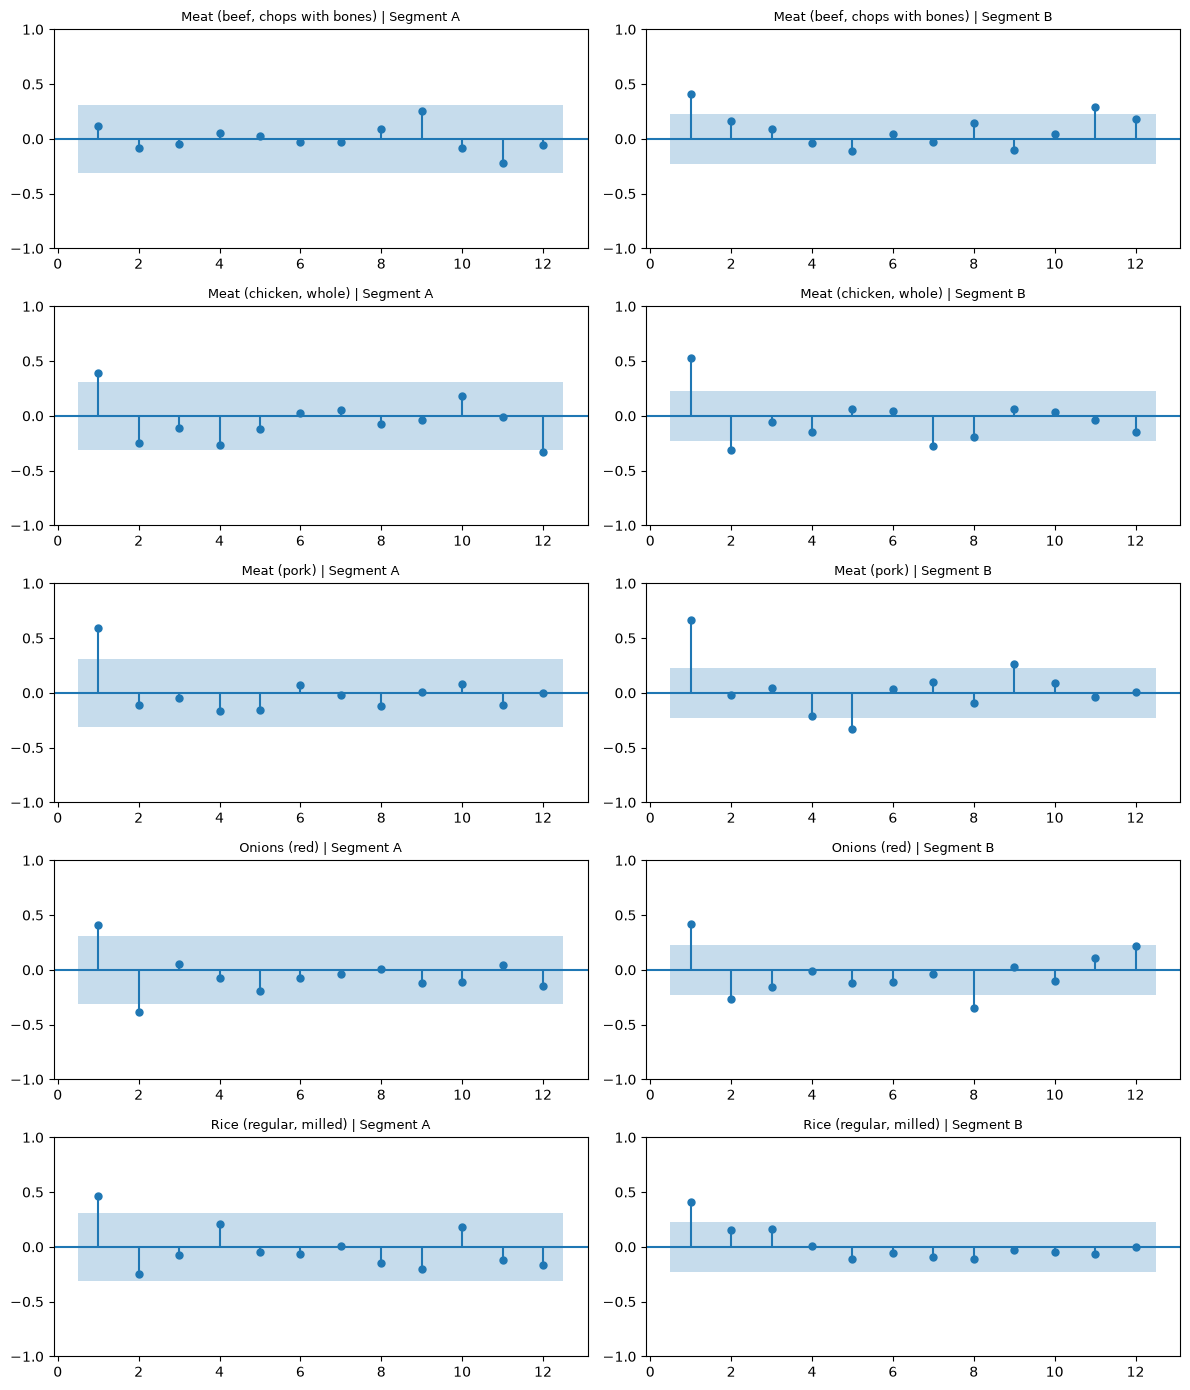

In [2]:
def corr_grid(kind):
    fig, axes = plt.subplots(len(COMS), 2, figsize=(12, 14))
    for i, c in enumerate(COMS):
        for j, s in enumerate(SEGS):
            ax = axes[i, j]
            x = dlogs[s][c]
            if kind == "acf":
                plot_acf(x, lags=12, zero=False, ax=ax)
            else:
                plot_pacf(x, lags=12, zero=False, method="ywm", ax=ax)
            ax.set_title(f"{c} | Segment {s}", fontsize=9)
    plt.tight_layout()
    plt.savefig(FIG / f"07_{kind}.png", dpi=150)
    plt.show()

corr_grid("acf")
corr_grid("pacf")

In [3]:
rows = []
for s in SEGS:
    for c in COMS:
        x = dlogs[s][c]
        r = acf(x, nlags=12, fft=False)
        lbp = acorr_ljungbox(x, lags=[12], return_df=True)["lb_pvalue"].iloc[0]
        rows.append({"commodity": c, "segment": s, "n": len(x),
                     "acf_lag1": round(r[1], 2), "acf_lag12": round(r[12], 2),
                     "ljungbox12_p": round(lbp, 3),
                     "band_95": round(1.96 / np.sqrt(len(x)), 2)})
ac = pd.DataFrame(rows)
display(ac)
ac.to_csv(TAB / "07_autocorr_summary.csv", index=False)

,commodity,segment,n,acf_lag1,acf_lag12,ljungbox12_p,band_95
0,"Meat (beef, chops with bones)",A,40,0.12,-0.13,0.568,0.31
1,"Meat (chicken, whole)",A,40,0.39,-0.29,0.006,0.31
2,Meat (pork),A,40,0.59,-0.01,0.007,0.31
3,Onions (red),A,40,0.41,0.01,0.272,0.31
4,"Rice (regular, milled)",A,40,0.46,-0.07,0.163,0.31
5,"Meat (beef, chops with bones)",B,73,0.41,0.30,0.000,0.23
6,"Meat (chicken, whole)",B,73,0.53,0.09,0.000,0.23
7,Meat (pork),B,73,0.66,0.18,0.000,0.23
8,Onions (red),B,73,0.42,0.37,0.000,0.23
9,"Rice (regular, milled)",B,73,0.41,-0.17,0.000,0.23


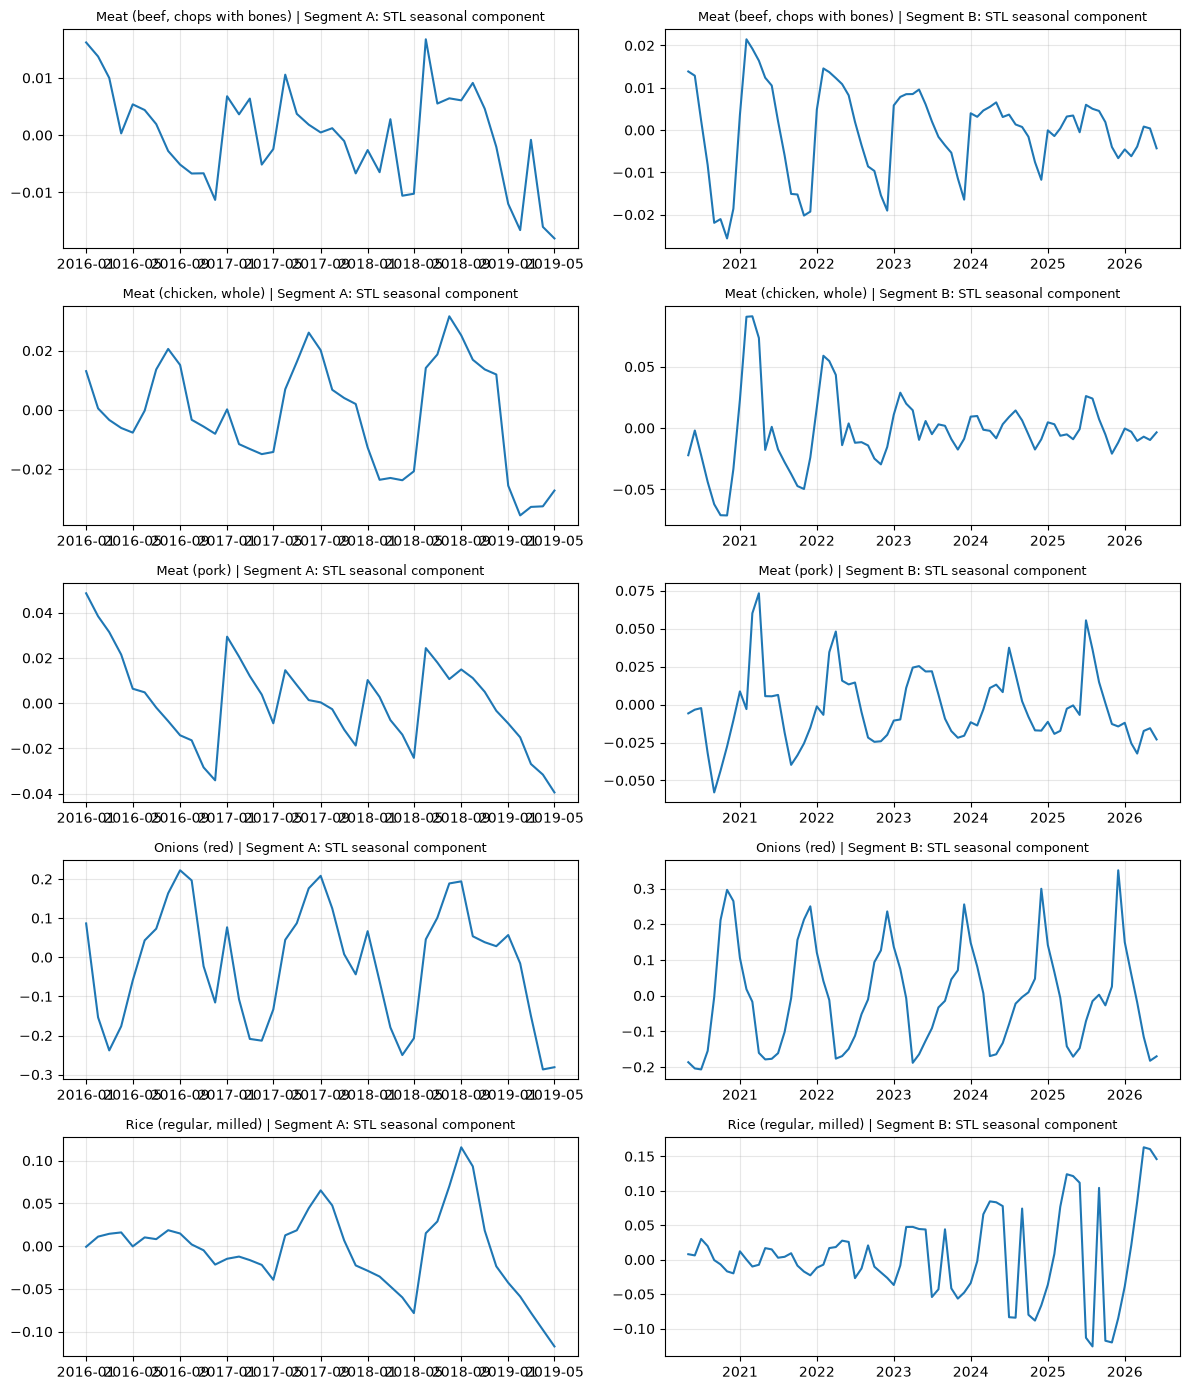

,commodity,segment,seasonal_strength,trend_strength,peak_month,trough_month,seasonal_range_pct
0,"Meat (beef, chops with bones)",A,0.06,0.98,6,4,1.8
1,"Meat (beef, chops with bones)",B,0.38,0.99,5,12,2.3
2,"Meat (chicken, whole)",A,0.00,0.72,8,4,4.5
3,"Meat (chicken, whole)",B,0.47,0.94,2,11,6.6
4,Meat (pork),A,0.23,0.93,1,12,3.9
5,Meat (pork),B,0.40,0.95,4,11,4.4
6,Onions (red),A,0.33,0.14,9,4,44.0
7,Onions (red),B,0.50,0.54,12,5,45.0
8,"Rice (regular, milled)",A,0.42,0.75,9,5,12.4
9,"Rice (regular, milled)",B,0.00,0.65,4,11,12.5


In [4]:
rows = []
fig, axes = plt.subplots(len(COMS), 2, figsize=(12, 14))
for i, c in enumerate(COMS):
    for j, s in enumerate(SEGS):
        y = logs[s][c]
        fit = STL(y.to_numpy(), period=12, robust=True).fit()
        fs = max(0, 1 - np.var(fit.resid) / np.var(fit.seasonal + fit.resid))   # seasonal strength
        ft = max(0, 1 - np.var(fit.resid) / np.var(fit.trend + fit.resid))      # trend strength
        prof = pd.Series(fit.seasonal, index=y.index).groupby(y.index.month).mean()
        rows.append({"commodity": c, "segment": s,
                     "seasonal_strength": round(fs, 2), "trend_strength": round(ft, 2),
                     "peak_month": int(prof.idxmax()), "trough_month": int(prof.idxmin()),
                     "seasonal_range_pct": round((prof.max() - prof.min()) * 100, 1)})
        axes[i, j].plot(y.index.to_timestamp(), fit.seasonal)
        axes[i, j].set_title(f"{c} | Segment {s}: STL seasonal component", fontsize=9)
        axes[i, j].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "07_stl_seasonal.png", dpi=150)
plt.show()

stl_tab = pd.DataFrame(rows)
display(stl_tab)
stl_tab.to_csv(TAB / "07_stl_strength.csv", index=False)